In [4]:
#Importing libraries
import numpy as np
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split # Sklearn package's randomized data splitting function

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
#Load and review data
rdata = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Melbourne_housing_FULL.csv')
rdata.head()

/tmp/ipykernel_1743/3638050861.py:2: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  rdata = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Melbourne_housing_FULL.csv')


,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,inf,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN
1,Airport West,154 Halsey Rd,3,t,PI,Nelson,3/9/2016,13.5,3042.0,3.0,...,303.0,225,2016.0,Moonee Valley City Council,-37.7180,144.8780,Western Metropolitan,3464.0,Detached Garage,840000.0
2,Albert Park,105 Kerferd Rd,2,h,S,hockingstuart,3/9/2016,3.3,3206.0,2.0,...,120.0,82,1900.0,Port Phillip City Council,-37.8459,144.9555,Southern Metropolitan,3280.0,Attached Garage,1275000.0
3,Albert Park,85 Richardson St,2,h,S,Thomson,3/9/2016,3.3,3206.0,2.0,...,159.0,inf,NaN,Port Phillip City Council,-37.8450,144.9538,Southern Metropolitan,3280.0,Indoor,1455000.0
4,Alphington,30 Austin St,3,h,SN,McGrath,3/9/2016,6.4,3078.0,3.0,...,174.0,122,2003.0,Darebin City Council,-37.7818,145.0198,Northern Metropolitan,2211.0,Parkade,NaN


In [6]:
rdata.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,inf,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN
1,Airport West,154 Halsey Rd,3,t,PI,Nelson,3/9/2016,13.5,3042.0,3.0,...,303.0,225,2016.0,Moonee Valley City Council,-37.7180,144.8780,Western Metropolitan,3464.0,Detached Garage,840000.0
2,Albert Park,105 Kerferd Rd,2,h,S,hockingstuart,3/9/2016,3.3,3206.0,2.0,...,120.0,82,1900.0,Port Phillip City Council,-37.8459,144.9555,Southern Metropolitan,3280.0,Attached Garage,1275000.0
3,Albert Park,85 Richardson St,2,h,S,Thomson,3/9/2016,3.3,3206.0,2.0,...,159.0,inf,NaN,Port Phillip City Council,-37.8450,144.9538,Southern Metropolitan,3280.0,Indoor,1455000.0
4,Alphington,30 Austin St,3,h,SN,McGrath,3/9/2016,6.4,3078.0,3.0,...,174.0,122,2003.0,Darebin City Council,-37.7818,145.0198,Northern Metropolitan,2211.0,Parkade,NaN


In [8]:
rdata.tail()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
34852,Reservoir,18 Elinda Pl,3,u,SP,RW,30/09/2017,12.0,3073.0,3.0,...,NaN,105.0,1990.0,Darebin City Council,-37.69769,145.02332,Northern Metropolitan,21650.0,Parkade,475000.0
34853,Roxburgh Park,14 Stainsby Cr,4,h,S,Raine,30/09/2017,20.6,3064.0,4.0,...,NaN,225.0,1995.0,Hume City Council,-37.63665,144.92976,Northern Metropolitan,5833.0,Underground,591000.0
34854,Springvale South,8 Bellbird Ct,4,h,PI,Barry,30/09/2017,22.2,3172.0,4.0,...,534.0,152.0,1970.0,Greater Dandenong City Council,-37.97037,145.15449,South-Eastern Metropolitan,4054.0,Carport,NaN
34855,Springvale South,30 Waddington Cr,3,h,S,Harcourts,30/09/2017,22.2,3172.0,3.0,...,544.0,NaN,NaN,Greater Dandenong City Council,-37.97751,145.14813,South-Eastern Metropolitan,4054.0,Detached Garage,780500.0
34856,Westmeadows,42 Pascoe St,4,h,S,Barry,30/09/2017,16.5,3049.0,4.0,...,813.0,140.0,1960.0,Hume City Council,-37.67631,144.89409,Northern Metropolitan,2474.0,Attached Garage,791000.0


Displaying Record Details

In [11]:
rdata.sample()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
12925,Broadmeadows,42 Tatura Cr,3,h,PI,Barry,10/2/2018,14.0,3047.0,3.0,...,615.0,NaN,NaN,Hume City Council,-37.67355,144.92207,Northern Metropolitan,4294.0,Attached Garage,565000.0


In [12]:
rdata.shape

(34857, 22)

In [13]:
rdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Method         34857 non-null  object 
 5   SellerG        34857 non-null  object 
 6   Date           34857 non-null  object 
 7   Distance       34856 non-null  float64
 8   Postcode       34856 non-null  float64
 9   Bedroom        26640 non-null  float64
 10  Bathroom       26631 non-null  float64
 11  Car            26129 non-null  float64
 12  Landsize       23047 non-null  float64
 13  BuildingArea   13760 non-null  object 
 14  YearBuilt      15551 non-null  float64
 15  CouncilArea    34854 non-null  object 
 16  Latitude       26881 non-null  float64
 17  Longtitude     26881 non-null  float64
 18  Region

In [14]:
rdata.describe()

,Rooms,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,YearBuilt,Latitude,Longtitude,Propertycount,Price
count,34857.000000,34856.000000,34856.000000,26640.000000,26631.000000,26129.000000,23047.000000,15551.000000,26881.000000,26881.000000,34854.000000,2.724700e+04
mean,3.031012,11.184929,3116.062859,3.084647,1.624798,1.728845,593.598993,1965.289885,-37.810634,145.001851,7572.888306,1.050173e+06
std,0.969933,6.788892,109.023903,0.980690,0.724212,1.010771,3398.841946,37.328178,0.090279,0.120169,4428.090313,6.414671e+05
min,1.000000,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.190430,144.423790,83.000000,8.500000e+04
25%,2.000000,6.400000,3051.000000,2.000000,1.000000,1.000000,224.000000,1940.000000,-37.862950,144.933500,4385.000000,6.350000e+05
50%,3.000000,10.300000,3103.000000,3.000000,2.000000,2.000000,521.000000,1970.000000,-37.807600,145.007800,6763.000000,8.700000e+05
75%,4.000000,14.000000,3156.000000,4.000000,2.000000,2.000000,670.000000,2000.000000,-37.754100,145.071900,10412.000000,1.295000e+06
max,16.000000,48.100000,3978.000000,30.000000,12.000000,26.000000,433014.000000,2106.000000,-37.390200,145.526350,21650.000000,1.120000e+07


In [15]:
rdata.dtypes

,0
Suburb,object
Address,object
Rooms,int64
Type,object
Method,object
SellerG,object
Date,object
Distance,float64
Postcode,float64
Bedroom,float64


# Checking Null Values

In [16]:
rdata.isnull()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
34853,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
34854,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
34855,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False


In [21]:
rdata.isnull().sum().sort_values(ascending=False)

,0
BuildingArea,21097
YearBuilt,19306
Landsize,11810
Car,8728
Bathroom,8226
Bedroom,8217
Latitude,7976
Longtitude,7976
Price,7610
CouncilArea,3


In [20]:
rdata.columns

Index(['Suburb', 'Address', 'Rooms', 'Type', 'Method', 'SellerG', 'Date',
       'Distance', 'Postcode', 'Bedroom', 'Bathroom', 'Car', 'Landsize',
       'BuildingArea', 'YearBuilt', 'CouncilArea', 'Latitude', 'Longtitude',
       'Regionname', 'Propertycount', 'ParkingArea', 'Price'],
      dtype='object')

# Checking duplicate values

In [18]:
rdata.duplicated().sum()

np.int64(0)

Clean the `BuildingArea` column



In [22]:
rdata["BuildingArea"] = pd.to_numeric(rdata["BuildingArea"], errors="coerce")

rdata["BuildingArea"].describe()

,BuildingArea
count,13749.0
mean,inf
std,NaN
min,0.0
25%,102.0
50%,136.0
75%,188.0
max,inf


Convert the sale date into useful numerical features

In [23]:
rdata["Date"] = pd.to_datetime(rdata["Date"], errors="coerce", dayfirst=True)

rdata["SaleYear"] = rdata["Date"].dt.year
rdata["SaleMonth"] = rdata["Date"].dt.month

rdata[["Date", "SaleYear", "SaleMonth"]].head()

,Date,SaleYear,SaleMonth
0,2016-09-03,2016,9
1,2016-09-03,2016,9
2,2016-09-03,2016,9
3,2016-09-03,2016,9
4,2016-09-03,2016,9


Remove rows where the target price is null


In [24]:
rdata = rdata.dropna(subset=["Price"]).copy()

print("Rows remaining:", len(rdata))
print("Missing prices:", rdata["Price"].isna().sum())

Rows remaining: 27247
Missing prices: 0


Plotting the Target variables


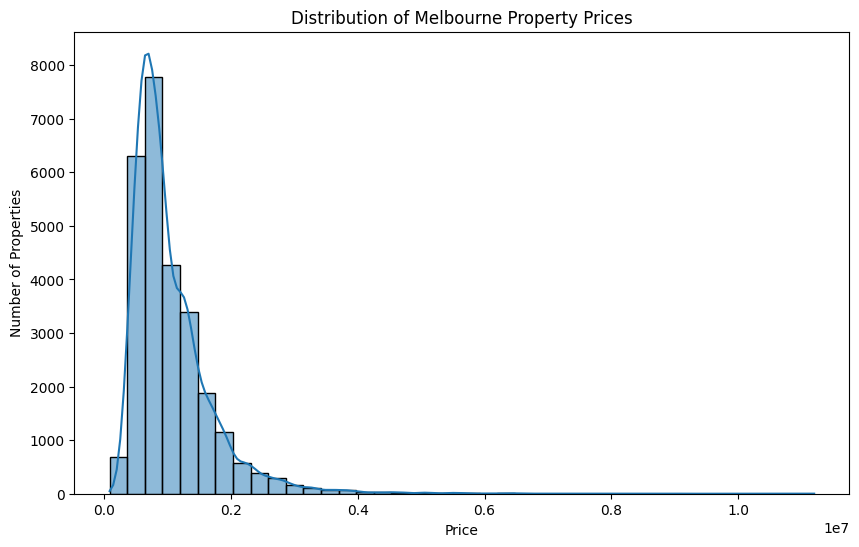

In [33]:
# Price distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=rdata, x='Price', bins=40, kde=True)
plt.title('Distribution of Melbourne Property Prices')
plt.xlabel('Price')
plt.ylabel('Number of Properties')
plt.show()

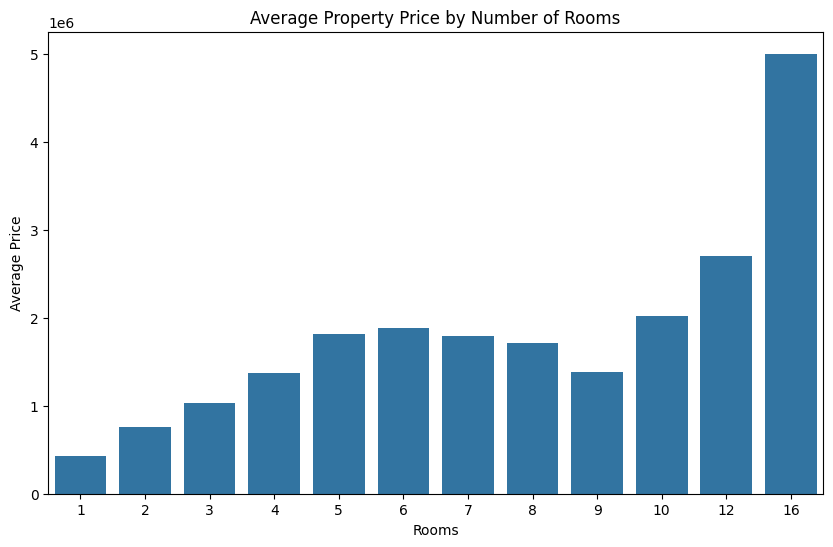

In [34]:
# Average price by number of rooms
plt.figure(figsize=(10, 6))
sns.barplot(data=rdata, x='Rooms', y='Price', estimator=np.mean, errorbar=None)
plt.title('Average Property Price by Number of Rooms')
plt.xlabel('Rooms')
plt.ylabel('Average Price')
plt.show()

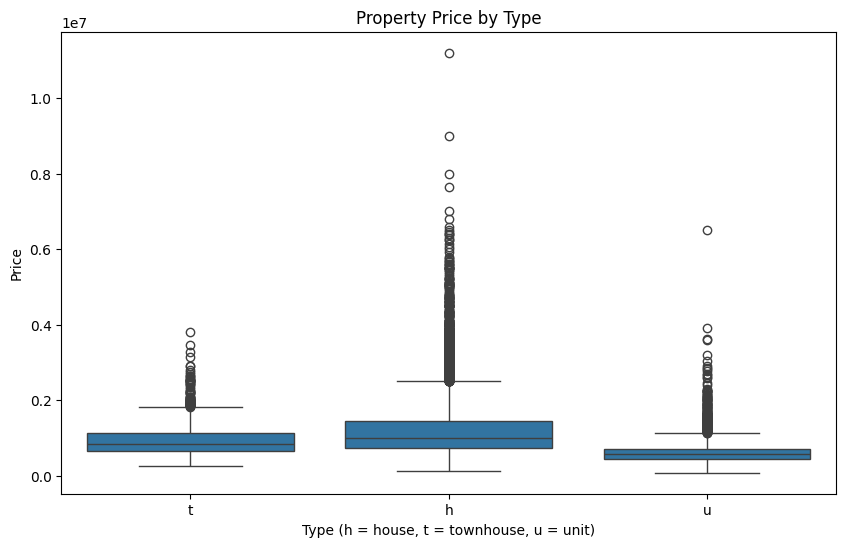

In [35]:
# Price by property type
plt.figure(figsize=(10, 6))
sns.boxplot(data=rdata, x='Type', y='Price')
plt.title('Property Price by Type')
plt.xlabel('Type (h = house, t = townhouse, u = unit)')
plt.ylabel('Price')
plt.show()

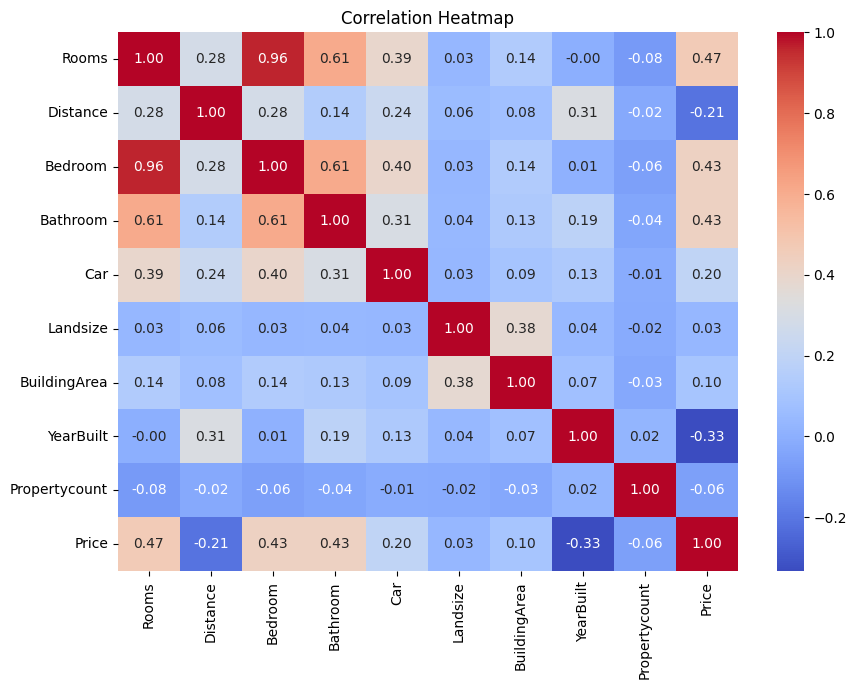

In [36]:
# Correlation heatmap for numeric columns
plt.figure(figsize=(10, 7))
numeric_df = rdata.select_dtypes(include='number')
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Separating Useful Values and Outlier Treatment

In [52]:

# Checking for outliers using the IQR method

numeric_cols = rdata.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = rdata[col].quantile(0.25)
    Q3 = rdata[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = rdata[
        (rdata[col] < lower_bound) |
        (rdata[col] > upper_bound)
    ]

    print("Outliers in", col, ":", len(outliers))


Outliers in Rooms : 23
Outliers in Distance : 1188
Outliers in Bedroom : 19
Outliers in Bathroom : 238
Outliers in Car : 1171
Outliers in Landsize : 453
Outliers in BuildingArea : 509
Outliers in YearBuilt : 28
Outliers in Propertycount : 727
Outliers in Price : 1278


In [31]:
# Keep the columns used in this practice model
selected_columns = [
    'Rooms', 'Type', 'Method', 'Distance', 'Bedroom', 'Bathroom', 'Car',
    'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Regionname',
    'Propertycount', 'Price'
]
rdata = rdata[selected_columns].copy()

# Convert columns that may contain text such as "inf" into numeric values
for col in ['BuildingArea']:
    if col in rdata.columns:
        rdata[col] = pd.to_numeric(rdata[col], errors='coerce')

# Price must be present for model training
rdata = rdata.dropna(subset=['Price'])
rdata.head()

,Rooms,Type,Method,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Propertycount,Price
1,3,t,PI,13.5,3.0,2.0,1.0,303.0,225.0,2016.0,Moonee Valley City Council,Western Metropolitan,3464.0,840000.0
2,2,h,S,3.3,2.0,1.0,0.0,120.0,82.0,1900.0,Port Phillip City Council,Southern Metropolitan,3280.0,1275000.0
3,2,h,S,3.3,2.0,1.0,0.0,159.0,inf,NaN,Port Phillip City Council,Southern Metropolitan,3280.0,1455000.0
5,4,h,S,6.4,3.0,2.0,4.0,853.0,263.0,1930.0,Darebin City Council,Northern Metropolitan,2211.0,2000000.0
6,3,h,S,6.4,3.0,2.0,2.0,208.0,inf,2013.0,Darebin City Council,Northern Metropolitan,2211.0,1110000.0


Splitting the Data

In [38]:
y = rdata['Price']
X = rdata.drop('Price', axis=1)

In [49]:
#Replacing Random, missing and incorrect values
rdata = rdata.replace([np.inf, -np.inf], np.nan)
categorical_cols = X.select_dtypes(include='object').columns
numeric_cols = X.select_dtypes(include=np.number).columns
for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())
categorical_cols = X.select_dtypes(include='object').columns
for col in categorical_cols:
    mode_value = X[col].mode()
    if len(mode_value) > 0:
        X[col] = X[col].fillna(mode_value[0])
    else:
        X[col] = X[col].fillna('Unknown')

print("Missing values remaining in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Missing values remaining in X: 0
Missing values in y: 0


In [50]:
# Linear Regression needs numeric inputs, so convert categories using one-hot encoding

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)
X.head()


,Rooms,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Propertycount,Type_t,...,CouncilArea_Wyndham City Council,CouncilArea_Yarra City Council,CouncilArea_Yarra Ranges Shire Council,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
1,3,13.5,3.0,2.0,1.0,303.0,225.0,2016.0,3464.0,1,...,0,0,0,0,0,0,0,0,1,0
2,2,3.3,2.0,1.0,0.0,120.0,82.0,1900.0,3280.0,0,...,0,0,0,0,0,0,0,1,0,0
3,2,3.3,2.0,1.0,0.0,159.0,133.0,1970.0,3280.0,0,...,0,0,0,0,0,0,0,1,0,0
5,4,6.4,3.0,2.0,4.0,853.0,263.0,1930.0,2211.0,0,...,0,0,0,0,1,0,0,0,0,0
6,3,6.4,3.0,2.0,2.0,208.0,133.0,2013.0,2211.0,0,...,0,0,0,0,1,0,0,0,0,0


In [51]:
# Replace infinite values with NaN in X and fill them with the column median
X = X.replace([np.inf, -np.inf], np.nan)
for col in X.select_dtypes(include=np.number).columns:
    X[col] = X[col].fillna(X[col].median())

# Independent variables
X = X

# Dependent variable
y = y

# Split X and y into training and test sets in a 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1
)

regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

LinearRegression()

In [53]:
for idx, col_name in enumerate(X_train.columns[:20]):
    print("The coefficient for {} is {}".format(
        col_name, regression_model.coef_[idx]
    ))

The coefficient for Rooms is 243271.81006050162
The coefficient for Distance is -35359.68965904938
The coefficient for Bedroom is -41497.11954517802
The coefficient for Bathroom is 151696.23910081908
The coefficient for Car is 50193.29253797228
The coefficient for Landsize is 3.3413207434059586
The coefficient for BuildingArea is 24.917287062300602
The coefficient for YearBuilt is -2414.3332328699653
The coefficient for Propertycount is 0.2398476484522689
The coefficient for Type_t is -224463.1258809811
The coefficient for Type_u is -427154.22368927416
The coefficient for Method_S is 66452.45687748646
The coefficient for Method_SA is 47286.85644902178
The coefficient for Method_SP is 36208.850348975946
The coefficient for Method_VB is 33096.19479380542
The coefficient for CouncilArea_Bayside City Council is 747343.1189684678
The coefficient for CouncilArea_Boroondara City Council is 660875.9800735378
The coefficient for CouncilArea_Brimbank City Council is -245186.36622890635
The coeff

In [54]:
intercept = regression_model.intercept_
print("The intercept for our model is {}".format(intercept))

The intercept for our model is 5258603.021191766


In [55]:
# Training R-squared
print("Training R²:", regression_model.score(X_train, y_train))

Training R²: 0.6182722931412044


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = regression_model.predict(X_test)

print("Testing R²:", r2_score(y_test, y_pred))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))

Testing R²: 0.6020038140970541
Mean Absolute Error (MAE): 260014.36101867442
Root Mean Squared Error (RMSE): 409825.46207750845


In [58]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})
comparison['Difference'] = comparison['Actual Price'] - comparison['Predicted Price']
comparison.head(10)

,Actual Price,Predicted Price,Difference
1779,475000.0,4.702518e+05,4748.241060
3875,1102000.0,9.126067e+05,189393.272855
2400,635000.0,1.067837e+06,-432837.037928
16229,1055000.0,1.076775e+06,-21774.965611
695,1650000.0,1.248530e+06,401470.051514
24170,1740000.0,1.838438e+06,-98437.918677
8405,1000000.0,1.534981e+06,-534980.620019
4333,1810000.0,1.719416e+06,90583.891073
34815,975000.0,1.557997e+06,-582996.869062
4749,678000.0,7.010602e+05,-23060.165640


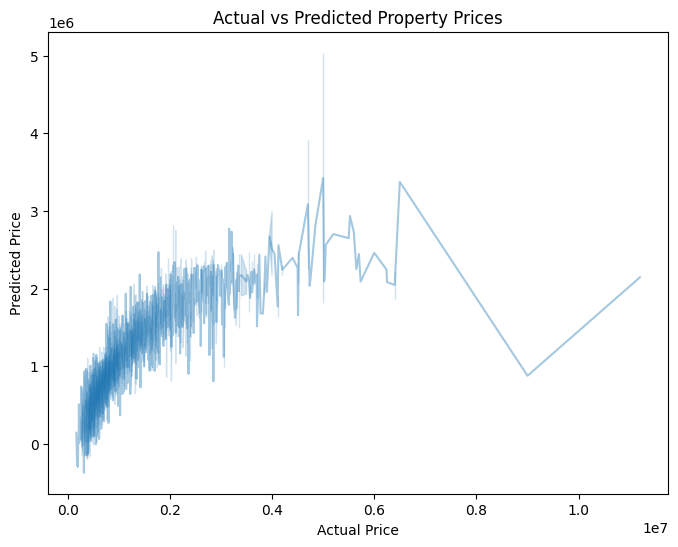

In [60]:
plt.figure(figsize=(8, 6))
sns.lineplot(x=y_test, y=y_pred, alpha=0.4)
plt.title('Actual vs Predicted Property Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [61]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model

# Use a small feature subset for this optional learning experiment
feature_subset = list(X_train.columns[:10])
X_train_small = X_train[feature_subset]
X_test_small = X_test[feature_subset]

poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_train2 = poly.fit_transform(X_train_small)
X_test2 = poly.transform(X_test_small)

poly_clf = linear_model.LinearRegression()
poly_clf.fit(X_train2, y_train)

y_pred_poly = poly_clf.predict(X_test2)
print("First 10 polynomial-model predictions:")
print(y_pred_poly[:10])

First 10 polynomial-model predictions:
[ 634377.19154736 1029468.37692155  790661.33985383 1292898.83442269
  709204.68910002 2420982.59281519  861048.35385682 2127745.96789114
  995044.15713486  645173.06506224]


In [62]:
# Training and testing R² for the interaction model
print("Polynomial model training R²:", poly_clf.score(X_train2, y_train))
print("Polynomial model testing R²:", poly_clf.score(X_test2, y_test))

Polynomial model training R²: 0.4694189181218794
Polynomial model testing R²: 0.4409181691395062
